# Question 4: Food prices and food shelf activity

Do more people arrive at food shelves when grocery prices rise? Does the response happen at once, or is there a delay? Does the response appear in all three of the food shelf metrics? Are there other cyclical patterns that prices do not explain?
Understanding the timing enables The Food Group to communicate expected changes in demand to food shelves and expected need to donors.

Datasets:

| File | Grain | Role |
|---|---|---|
| `org_FSStats.xlsx` | Site × month | Monthly households served (used as a visit proxy), individuals served, and pounds distributed |
| `Q4-FRED-CPI-Midwest.xlsx` | Census Midwest region × month (Jan 1978 – Jul 2026 after cutoff; not seasonally adjusted) | Grocery price measure: CPI-U Food at Home, Midwest (series `CUUR0200SAF11`, index 1982–84 = 100). Used as the explanatory price variable (levels converted to month-over-month % change; year-over-year % change used as a robustness check) to test whether, and with what lag, food-shelf activity responds to grocery prices |



Sources:
- U.S. Bureau of Labor Statistics, via Federal Reserve Bank of St. Louis (FRED). *Consumer Price Index for All Urban Consumers: Food at Home in Midwest Urban* (`CUUR0200SAF11`), monthly, not seasonally adjusted, index 1982–84=100. https://fred.stlouisfed.org/series/CUUR0200SAF11 (data updated 2026-09-11; accessed 2026-09-28)

**Why this source:** We chose the Midwest Urban food-at-home CPI over two alternatives.
- **National food-at-home CPI:** Less relevant to Minnesota prices.
- **Minneapolis–St. Paul CPI:** Closer geographically, but published only bimonthly ([BLS](https://www.bls.gov/regions/midwest/news-release/consumerpriceindex_minneapolis.htm)). The lag analysis requires a monthly series, so the bimonthly series cannot be used.

Food at home was used rather than all-items CPI because the question concerns grocery prices specifically. The not-seasonally-adjusted series was used because seasonality is handled explicitly in the analysis (quarter controls and calendar-month adjustments).

## 1. Setup

### 1.1 Load data

> **Purpose:** This step loads the two raw inputs the whole Q4 analysis depends on — the organizer-provided food shelf activity data (`org_FSStats`) and the BLS CPI series for food-at-home prices in the Midwest region — and prints their shapes/columns as a first sanity check before any cleaning or merging begins.

In [44]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import statsmodels.formula.api as smf
from google.colab import drive

drive.mount('/content/drive')

pd.set_option("display.max_columns", None)

DATA_DIR = "/content/drive/MyDrive/MinneMUDAC 26 for BU/Suji/Data/Q4"

FS_PATH  = f"{DATA_DIR}/org_FSStats.xlsx"
CPI_PATH = f"{DATA_DIR}/Q4-FRED-CPI-Midwest.xlsx"

fs_raw = pd.read_excel(
    FS_PATH,
    sheet_name="org_FSStats"
)

cpi_raw = pd.read_excel(
    CPI_PATH,
    sheet_name="Monthly"
)

for name, df in [("org_FSStats", fs_raw), ("CPI Midwest", cpi_raw)]:
    print(f"{name:15s} {df.shape}")
    print("   ", list(df.columns)[:30], "\n")

print("=== CPI Data Tail ===")
print(cpi_raw.tail())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
org_FSStats     (28287, 58)
    ['__ID', '_id_site', '_Year', '_Month', 'DateForSearch', 'zzCreationTS', 'zzModificationTS', 'AdultsReg', 'ChildrenReg', 'HouseholdsReg', 'IndividualsReg', 'Meals', 'Misc', 'People', 'PoundsReg', 'SeniorsReg', 'Snacks', 'UniqueVisitsReg', 'County', 'FederalDistrict', 'StateDistrict', 'FoodBank', 'ChildrenExtra', 'ChildrenProduce', 'ChildrenHoliday', 'AdultsExtra', 'AdultsProduce', 'AdultsHoliday', 'IndividualsExtra', 'SeniorsExtra'] 

CPI Midwest     (585, 2)
    ['observation_date', 'CUUR0200SAF11'] 

=== CPI Data Tail ===
    observation_date  CUUR0200SAF11
580       2026-04-01        302.196
581       2026-05-01        304.128
582       2026-06-01        302.643
583       2026-07-01        302.475
584       2026-08-01        303.650


> **What this result means:** Both files loaded successfully. FSStats has 28,287 rows and 58 columns, confirming the full organizer dataset is present (grain = site × month). The CPI file's tail shows it currently extends through August 2026 — exactly the month the competition rules forbid using — so the next step truncates it before it can leak into any downstream calculation.

### 1.2 Apply the August 2026 rule

> **Purpose:** The competition's hard disqualification rule bars using any August 2026 data from any source. This section truncates the CPI series to July 2026 immediately after loading, before any other processing, so the rule can't accidentally be violated later in the pipeline.

In [ ]:
# Competition rule:
# Never use August 2026 data from any source.
# We therefore truncate both datasets at July 2026 immediately after loading.

cpi_raw["observation_date"] = pd.to_datetime(
    cpi_raw["observation_date"]
)

cpi = cpi_raw[
    cpi_raw["observation_date"] <= "2026-07-31"
].copy()

print(
    "CPI last date after truncation:",
    cpi["observation_date"].max()
)

assert (
    cpi["observation_date"].max()
    <= pd.Timestamp("2026-07-31")
    ), "August data leaked in!"

CPI last date after truncation: 2026-07-01 00:00:00


> **What this result means:** The truncation worked as intended — the last CPI date is now 2026-07-01, and the assertion confirms no August 2026 row remains. The CPI series is now compliant with the competition rule going forward.

### 1.3 Fill the October 2025 CPI gap

In [ ]:
# The FRED CPI series has exactly one gap in our analysis window: 2025-10-01.
# BLS did not collect CPI data from Oct 1 to Nov 12, 2025 (lapse in appropriations),
# so October 2025 was never published and November 2025 rests on partial-month data.
# Source: https://www.bls.gov/cpi/additional-resources/2025-federal-government-shutdown-impact-cpi-faq.htm
# A sensitivity check later re-runs the key result with Oct and Nov 2025 excluded.
# Even monthly spacing that pct_change() and the lag analysis assume
# (Sep -> Nov would look like a single 1-month step instead of 2).
# Linear interpolation keeps the monthly cadence intact.

cpi = cpi.sort_values("observation_date").reset_index(drop=True)
missing_before = cpi["CUUR0200SAF11"].isna().sum()

cpi["CUUR0200SAF11"] = cpi["CUUR0200SAF11"].interpolate(method="linear")

print(f"CPI missing values: {missing_before} -> {cpi['CUUR0200SAF11'].isna().sum()}")
print(cpi[cpi['observation_date'] == '2025-10-01'])

CPI missing values: 1 -> 0
    observation_date  CUUR0200SAF11
574       2025-10-01        297.908


> **What this result means:** The CPI series had exactly one missing value in the analysis window: October 2025. During the 2025 federal government shutdown, BLS did not collect CPI data from October 1 to November 12, 2025, so the October index was never published and the November index is based on partial-month data ([BLS](https://www.bls.gov/cpi/additional-resources/2025-federal-government-shutdown-impact-cpi-faq.htm)). Linear interpolation fills October (297.908) so the even monthly spacing that `pct_change()` and the lag analysis rely on stays intact. The October and November 2025 % changes are therefore partly artificial; the sensitivity check in 8.4 shows the main result holds when both months are excluded.

## 2. Clean the food-shelf data

### 2.1 Standardize county labels

In [ ]:
# FSStats splits some counties into sub-regions.
# Standardize these labels so each county has one common name.

county_crosswalk = {
    "Hennepin-Minneapolis": "Hennepin",
    "Hennepin-Suburbs": "Hennepin",
    "Ramsey-Saint Paul": "Ramsey",
    "Ramsey-Suburbs": "Ramsey",
}

fs = fs_raw.copy()

fs["County_clean"] = fs["County"].replace(
    county_crosswalk
)

print(
    "Unique counties before:",
    fs_raw["County"].nunique()
)

print(
    "Unique counties after:",
    fs["County_clean"].nunique()
)

Unique counties before: 91
Unique counties after: 87


> **What this result means:** Standardizing the split county labels (e.g., merging Hennepin-Minneapolis/Hennepin-Suburbs into a single 'Hennepin') reduced the county count from 91 raw labels to 87 standardized counties — Minnesota's actual county count. This is necessary before any county-level or statewide aggregation; without it, Hennepin and Ramsey's activity would be split across sub-labels and effectively undercounted relative to every other county reported as a single unit.

### 2.2 Repair Households/Individuals errors

> **Purpose:** By the data dictionary's definitions, IndividualsReg (adults + children + seniors) should never be smaller than HouseholdsReg (unique households). Rows that break this badly are data-entry errors. The Data Catalog notes that individuals are self-reported while households are counted at the point of service, so either field can be the wrong one. This step decides the direction case by case and repairs the bad value instead of deleting it.

In [ ]:
# Two error types, handled in the direction the evidence points:
#  (1) HouseholdsReg >= 2x IndividualsReg  -> HouseholdsReg is implausible
#  (2) IndividualsReg == 0 while HouseholdsReg > 0 -> IndividualsReg is implausible
# Instead of setting values to NaN (which creates artificial dips in the monthly
# totals), impute from each site's own typical households-per-individual ratio.

HOUSEHOLD_TYPO_RATIO = 2.0

ind_zero = (fs["IndividualsReg"] == 0) & (fs["HouseholdsReg"] > 0)
ratio = fs["HouseholdsReg"] / fs["IndividualsReg"].replace(0, np.nan)
hh_bad = ratio >= HOUSEHOLD_TYPO_RATIO

clean = ~(hh_bad | ind_zero) & fs["HouseholdsReg"].gt(0) & fs["IndividualsReg"].gt(0)
clean_ratio = fs.loc[clean, "HouseholdsReg"] / fs.loc[clean, "IndividualsReg"]
site_ratio = clean_ratio.groupby(fs.loc[clean, "_id_site"]).median()
site_r = fs["_id_site"].map(site_ratio).fillna(clean_ratio.median())

show_cols = ["_id_site", "County_clean", "_Year", "_Month",
             "HouseholdsReg", "IndividualsReg", "PoundsReg"]
before = fs.loc[hh_bad | ind_zero, show_cols].copy()

fs["hh_imputed"] = hh_bad
fs["ind_imputed"] = ind_zero
fs.loc[hh_bad, "HouseholdsReg"] = (fs.loc[hh_bad, "IndividualsReg"] * site_r[hh_bad]).round()
fs.loc[ind_zero, "IndividualsReg"] = (fs.loc[ind_zero, "HouseholdsReg"] / site_r[ind_zero]).round()

after = fs.loc[hh_bad | ind_zero, ["HouseholdsReg", "IndividualsReg"]]
print(f"HouseholdsReg imputed: {hh_bad.sum()} rows | IndividualsReg imputed: {ind_zero.sum()} rows")
print(before.join(after, rsuffix="_fixed").to_string())

HouseholdsReg imputed: 22 rows | IndividualsReg imputed: 4 rows
       _id_site County_clean  _Year  _Month  HouseholdsReg  IndividualsReg  PoundsReg  HouseholdsReg_fixed  IndividualsReg_fixed
58      14681.1     Hennepin   2022       1         3118.0           670.0    15311.0                186.0                 670.0
3624    14681.1     Hennepin   2022       2         3828.0           699.0    15514.0                194.0                 699.0
5223    15298.0     Hennepin   2022      11         2147.0           985.0    50279.0                737.0                 985.0
5774     1267.0     Hennepin   2022      12          500.0           104.0     7380.0                 43.0                 104.0
7487    14919.0     Beltrami   2023       3           22.0             0.0      595.0                 22.0                  27.0
7835    14919.0     Beltrami   2023       4           39.0             0.0     1298.0                 39.0                  48.0
9095     1245.0         Polk   20

> **What this result means:** 26 site-months were repaired. In 22, HouseholdsReg was at least 2x IndividualsReg (e.g., Waseca 2023-07: 273,385 households vs. 646 individuals; Ramsey 2025-03 and Dakota 2024-04, where the pounds figure was copied into the households field). For these, HouseholdsReg was re-estimated from the site's own typical households-per-individual ratio. In 4 (Beltrami 2023-03/04, McLeod 2024-01), IndividualsReg was 0 while households were reported, so IndividualsReg was re-estimated instead.
>
> Imputing rather than setting values to NaN matters for a time series. A missing value is summed as zero, which would create an artificial dip in that month's statewide total; Ramsey 2025-03 alone is about 3,500 households. Overshoots below 2x are treated as reporting noise and left unchanged.

### 2.3 Inspect agency types

> **Purpose:** Before deciding which site types count as 'food shelf' activity, we need to see every distinct AgencyType value as stored in the raw data, including any inconsistent spelling or duplicate categories that could cause rows to be silently dropped later.

In [ ]:
print(
    fs["AgencyType"]
    .value_counts(dropna=False)
)

AgencyType
Brick and Mortar Site      14751
Food Shelf                  7406
Outreach Program            2480
Meal Program                1593
On-Site Meal Programs       1040
Mobile                       354
Tribal Program               223
College Campus Program       165
NaN                          138
Meal Programs                 89
Other Non-Profit              22
Agency or Tribal Nation       17
Brick and Mortar Sites         9
Name: count, dtype: int64


> **What this result means:** The raw AgencyType field contains 11 distinct non-null categories, but two of them are duplicated due to singular/plural spelling: 'Brick and Mortar Site' (14,751 rows) vs. 'Brick and Mortar Sites' (9 rows), and 'Meal Program' (1,593 rows) vs. 'Meal Programs' (89 rows). Left as-is, a filter matching only the singular spelling would silently exclude those 9 + 89 rows.

In [ ]:
# "Brick and Mortar Site" (14,751 rows) and "Brick and Mortar Sites"
# (9 rows, plural) are the same category with inconsistent spelling.
# Normalize before filtering so these 9 rows aren't silently dropped.

fs["AgencyType_clean"] = fs["AgencyType"].replace({
    "Brick and Mortar Sites": "Brick and Mortar Site",
    "Meal Programs": "Meal Program",
})

print(fs["AgencyType_clean"].value_counts(dropna=False))

AgencyType_clean
Brick and Mortar Site      14760
Food Shelf                  7406
Outreach Program            2480
Meal Program                1682
On-Site Meal Programs       1040
Mobile                       354
Tribal Program               223
College Campus Program       165
NaN                          138
Other Non-Profit              22
Agency or Tribal Nation       17
Name: count, dtype: int64


> **What this result means:** After merging the plural variants into their singular forms, 'Brick and Mortar Site' now correctly totals 14,760 rows (14,751 + 9) and 'Meal Program' totals 1,682 rows (1,593 + 89). AgencyType_clean is now the safe column to filter on, since it no longer has spelling-based duplicate categories.

### 2.4 Define food-shelf-like sites

> **Purpose:** Q4 is about food-shelf activity specifically, not every program type org_FSStats tracks (meal programs, mobile distribution, outreach, etc.). This section defines which AgencyType_clean categories represent an actual food shelf / brick-and-mortar distribution site, so the rest of the analysis isn't diluted by unrelated program types.

In [ ]:
# Keep only food-shelf-like sites.
# These categories represent the physical food shelf sites used
# for the primary statewide food-shelf activity analysis.

FOOD_SHELF_TYPES = [
    "Food Shelf",
    "Brick and Mortar Site"
]

fs_filtered = fs[
    fs["AgencyType_clean"].isin(FOOD_SHELF_TYPES)
].copy()

In [ ]:
# Site-level calendar date (invalid month codes 0/15 become NaT and are excluded later)
fs_filtered["date"] = pd.to_datetime(
    dict(year=fs_filtered["_Year"], month=fs_filtered["_Month"], day=1), errors="coerce"
)

> **What this result means:** This cell keeps only rows where AgencyType_clean is 'Food Shelf' or 'Brick and Mortar Site'. Using AgencyType_clean lets the 9 'Brick and Mortar Sites' rows be included instead of silently dropped. It also builds a site-level `date` column, used later to count reporting sites per month and to build the balanced-panel check.
>
> We deliberately do not filter on current `isActive` status. For a time series, dropping sites that closed later would erase their real past activity.

### 2.5 Aggregate to county-month

> **Purpose:** org_FSStats is recorded at the site-month level (one row per food shelf site per month). To build a usable time series, visits/pounds/individuals need to be summed up to the county-month level, which is the grain the rest of the Q4 analysis works at.

In [ ]:
panel = (
    fs_filtered
    .groupby(
        ["County_clean", "_Year", "_Month"],
        as_index=False
    )
    .agg(
        visits=(
            "HouseholdsReg",
            lambda x: x.sum(min_count=1)
        ),
        pounds=(
            "PoundsReg",
            lambda x: x.sum(min_count=1)
        ),
        individuals=(
            "IndividualsReg",
            lambda x: x.sum(min_count=1)
        ),
    )
)

print("Initial panel shape:", panel.shape)
panel.head()

Initial panel shape: (4735, 6)


,County_clean,_Year,_Month,visits,pounds,individuals
0,Aitkin,2022,1,222.0,11249.0,547.0
1,Aitkin,2022,2,222.0,11249.0,547.0
2,Aitkin,2022,3,234.0,12729.0,562.0
3,Aitkin,2022,4,297.0,14382.0,597.0
4,Aitkin,2022,5,236.0,13290.0,593.0


> **What this result means:** The aggregation produced 4,735 county-month rows across 6 columns. `sum(min_count=1)` is used so a county-month with all-missing source values stays NaN rather than being silently coerced to 0, which would otherwise understate activity in a month where a site simply didn't report.

### 2.6 Remove invalid months

> **Purpose:** The `_Month` field is expected to range from 1-12, but a handful of rows carry placeholder/error codes. These need to be identified and removed before a calendar date can be constructed, since a month of 0 or 15 has no valid date.

In [ ]:
# Identify invalid or unknown month codes before creating dates.

invalid_months = panel.loc[
    ~panel["_Month"].between(1, 12),
    [
        "County_clean",
        "_Year",
        "_Month",
        "visits",
        "pounds",
        "individuals"
    ]
]

print("Invalid / unknown month records:")
print(invalid_months)

print(
    "\nNumber of invalid-month rows:",
    len(invalid_months)
)

# Monthly analysis requires a valid calendar month.
# Do not arbitrarily assign month 0 or month 15 to a real month.
panel = panel[
    panel["_Month"].between(1, 12)
].copy()

Invalid / unknown month records:
     County_clean  _Year  _Month  visits    pounds  individuals
452       Carlton   2023       0   410.0   32701.0       1088.0
838          Cook   2023       0    96.0    6330.0        182.0
2049         Lake   2023       0   387.0   25426.0        862.0
3272         Polk   2023      15    33.0    2043.0         69.0
3921    St. Louis   2023       0  4938.0  343528.0      12098.0

Number of invalid-month rows: 5


> **What this result means:** Only 5 of the 4,735 county-month rows have an invalid month code (four with month=0, one with month=15, scattered across Carlton, Cook, Lake, Polk, and St. Louis counties in 2023). This is a small enough share that dropping them outright is safe and won't bias the statewide series.

### 2.7 Create monthly date and apply cutoff

> **Purpose:** With valid month codes confirmed, this section builds an actual first-of-month `date` column (needed for time-series operations like merging, plotting, and pct_change) and applies the same July 2026 cutoff used for CPI, so the activity panel and the CPI series stay aligned to the same compliant date range.

In [ ]:
# Create a valid first-of-month date.

panel["date"] = pd.to_datetime(
    panel["_Year"].astype(str)
    + "-"
    + panel["_Month"].astype(str).str.zfill(2)
    + "-01"
)

# Apply the same July 2026 cutoff used for CPI.
panel = panel[
    panel["date"] <= "2026-07-31"
].copy()

print("Panel shape:", panel.shape)
print("Panel date range:", panel["date"].min(), "to", panel["date"].max())

panel.head()

Panel shape: (4730, 7)
Panel date range: 2022-01-01 00:00:00 to 2026-07-01 00:00:00


,County_clean,_Year,_Month,visits,pounds,individuals,date
0,Aitkin,2022,1,222.0,11249.0,547.0,2022-01-01
1,Aitkin,2022,2,222.0,11249.0,547.0,2022-02-01
2,Aitkin,2022,3,234.0,12729.0,562.0,2022-03-01
3,Aitkin,2022,4,297.0,14382.0,597.0,2022-04-01
4,Aitkin,2022,5,236.0,13290.0,593.0,2022-05-01


> **What this result means:** After the cutoff, the panel has 4,730 rows spanning January 2022 through July 2026 — the full, compliant analysis window, with no August 2026 data present.

## 3. Build the statewide monthly series

### 3.1 Merge CPI

> **Purpose:** To test any relationship between food prices and food-shelf activity, the CPI series needs to be joined onto the county-month activity panel using a shared year-month key.

In [ ]:
# Convert CPI dates into the same year-month keys used by FSStats.

cpi["_Year"] = cpi["observation_date"].dt.year
cpi["_Month"] = cpi["observation_date"].dt.month

cpi = cpi.rename(
    columns={
        "CUUR0200SAF11":
        "cpi_food_at_home_midwest"
    }
)

merged = panel.merge(
    cpi[
        [
            "_Year",
            "_Month",
            "cpi_food_at_home_midwest"
        ]
    ],
    on=["_Year", "_Month"],
    how="left"
)

print(
    "Rows with missing CPI after merge:",
    merged["cpi_food_at_home_midwest"].isna().sum()
)

print(
    "Unique months with missing CPI:",
    merged.loc[
        merged["cpi_food_at_home_midwest"].isna(),
        "date"
    ].nunique()
)

merged.head()

Rows with missing CPI after merge: 0
Unique months with missing CPI: 0


,County_clean,_Year,_Month,visits,pounds,individuals,date,cpi_food_at_home_midwest
0,Aitkin,2022,1,222.0,11249.0,547.0,2022-01-01,255.381
1,Aitkin,2022,2,222.0,11249.0,547.0,2022-02-01,258.599
2,Aitkin,2022,3,234.0,12729.0,562.0,2022-03-01,263.145
3,Aitkin,2022,4,297.0,14382.0,597.0,2022-04-01,267.001
4,Aitkin,2022,5,236.0,13290.0,593.0,2022-05-01,271.278


> **What this result means:** Zero rows and zero months are missing a CPI value after the merge — a direct result of interpolating the 2025-10 CPI gap earlier (see 1.3). Without that fix, this merge would have left October 2025 with a missing CPI value across every county, forcing that month to be dropped from any CPI-based calculation.

### 3.2 Create the Minnesota statewide monthly series

> **Purpose:** Q4's headline analysis looks at Minnesota as a whole, not county-by-county, so this step sums the county-level panel up to one statewide number per month for visits, individuals, and pounds, alongside the single statewide CPI value for that month.

In [ ]:
statewide = (
    merged
    .groupby("date", as_index=False)
    .agg(
        visits=("visits", "sum"),
        individuals=("individuals", "sum"),
        pounds=("pounds", "sum"),
        cpi=("cpi_food_at_home_midwest", "first"),
    )
    .sort_values("date")
)

# Remove months without a CPI observation for CPI-based analyses.
statewide = statewide.dropna(
    subset=["cpi"]
).copy()

print(
    "Statewide months:",
    statewide["date"].nunique()
)

print(
    "Date range:",
    statewide["date"].min(),
    "to",
    statewide["date"].max()
)

statewide.head()

Statewide months: 55
Date range: 2022-01-01 00:00:00 to 2026-07-01 00:00:00


,date,visits,individuals,pounds,cpi
0,2022-01-01,118080.0,346639.0,8474922.33,255.381
1,2022-02-01,157470.0,335112.0,7422252.61,258.599
2,2022-03-01,139456.0,417953.0,9057370.35,263.145
3,2022-04-01,143672.0,456672.0,9411338.50,267.001
4,2022-05-01,142483.0,458198.0,9592122.03,271.278


> **What this result means:** The statewide series covers 55 months (January 2022 – July 2026) with no missing CPI values. January 2022 shows 118,080 households after the data repairs above.
>
> Note on naming: the `visits` column holds HouseholdsReg, i.e., households served. It is used as a visit proxy, not as a visit count; section 3.3 quantifies the difference.

### 3.3 Sanity check: households vs. TFG published visit totals

> **Purpose:** Judges will ask where our "visits" numbers come from. TFG publishes statewide food-shelf visits (TFG MFSP Grant Funding deck, slide 7), so this compares our proxy against the eight published months.

In [ ]:
# TFG publishes statewide food-shelf VISITS (source: TFG "MFSP Grant Funding" deck, slide 7).
# HouseholdsReg counts unique households per site-month, so it should be lower.
tfg_published = pd.Series({
    "2025-01-01": 775832, "2025-02-01": 719103, "2025-03-01": 756863, "2025-04-01": 782437,
    "2026-01-01": 717575, "2026-02-01": 850781, "2026-03-01": 859076, "2026-04-01": 823884,
})
tfg_published.index = pd.to_datetime(tfg_published.index)

fs_all = fs.assign(date=pd.to_datetime(
    dict(year=fs["_Year"], month=fs["_Month"], day=1), errors="coerce"))
hh_all_types = fs_all.groupby("date")["HouseholdsReg"].sum()

check = statewide.set_index("date").loc[tfg_published.index, ["visits", "individuals"]]
check = check.rename(columns={"visits": "households_foodshelf_types"})
check["households_all_agency_types"] = hh_all_types.reindex(check.index)
check["tfg_published_visits"] = tfg_published
check["foodshelf_hh_to_visits"] = check["households_foodshelf_types"] / check["tfg_published_visits"]
check["all_types_hh_to_visits"] = check["households_all_agency_types"] / check["tfg_published_visits"]
check["individuals_to_visits"] = check["individuals"] / check["tfg_published_visits"]
print(check.round(3).to_string())

            households_foodshelf_types  individuals  households_all_agency_types  tfg_published_visits  foodshelf_hh_to_visits  all_types_hh_to_visits  individuals_to_visits
2025-01-01                    218514.0     678410.0                     248063.0                775832                   0.282                   0.320                  0.874
2025-02-01                    212430.0     625123.0                     241421.0                719103                   0.295                   0.336                  0.869
2025-03-01                    211742.0     633908.0                     247939.0                756863                   0.280                   0.328                  0.838
2025-04-01                    229358.0     679452.0                     263231.0                782437                   0.293                   0.336                  0.868
2026-01-01                    199827.0     585451.0                     238536.0                717575                   0.278    

> **What this result means:** HouseholdsReg is not a visit count. Food-shelf-type households equal 26–30% of TFG's published visits (32–34% with all agency types). This is consistent with HouseholdsReg counting each household once per site-month, while a visit counts every trip.
>
> Two consequences:
> 1. Levels from this notebook must be labeled "households served," never "visits."
> 2. The ratio is stable across months (0.26–0.30), so month-to-month % changes in households are a reasonable proxy for % changes in visits. That is the measure the Q4 analysis uses.
>
> One caution: the ratio is lower in early 2026 than in early 2025. TFG visits rose 18% from February 2025 to February 2026, while households rose only 5%. Our proxy may therefore understate the 2026 surge if it came from more frequent visits by the same households.

### 3.4 Data quality: number of reporting sites per month

Largest drops in reporting sites (%):
 date
2024-01-01   -8.4
2022-04-01   -2.9
2022-02-01   -2.2
2023-03-01   -2.1
2023-08-01   -1.9
Name: _id_site, dtype: float64

Largest jumps in reporting sites (%):
 date
2022-03-01    3.5
2022-07-01    3.4
2022-05-01    2.5
2024-03-01    1.8
2022-06-01    1.5
Name: _id_site, dtype: float64


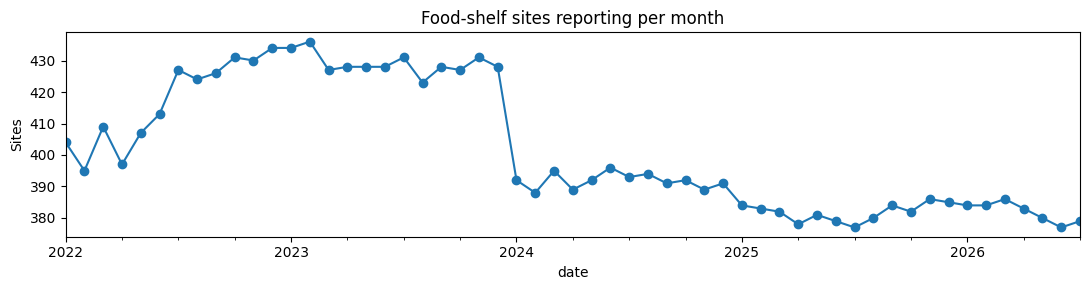

In [41]:
fs_valid = fs_filtered[fs_filtered["date"].notna() & (fs_filtered["date"] <= "2026-07-31")]
sites_per_month = fs_valid.groupby("date")["_id_site"].nunique()

site_change = sites_per_month.pct_change().mul(100).round(1)
print("Largest drops in reporting sites (%):\n", site_change.nsmallest(5))
print("\nLargest jumps in reporting sites (%):\n", site_change.nlargest(5))

fig, ax = plt.subplots(figsize=(11, 3))
sites_per_month.plot(ax=ax, marker="o")
ax.set_title("Food-shelf sites reporting per month"); ax.set_ylabel("Sites")
plt.tight_layout(); plt.show()

> **What this result means:** The number of reporting food-shelf sites is not constant. It rose from about 395 in early 2022 to a peak of 436 in early 2023, held near 425–430 through 2023, fell 8.4% in January 2024 (to about 392), and drifted down to 377–386 afterward.
>
> Because the statewide series sums across sites, these shifts move the totals regardless of demand. The January 2024 step-down, in particular, lowers that month's % change for reasons unrelated to prices. The balanced-panel check in 8.3 re-runs the lag analysis using only sites that reported every month.

## 4. Q4-A — Do more people arrive at food shelves when grocery prices rise?

### 4.1 Households served vs. food-at-home CPI

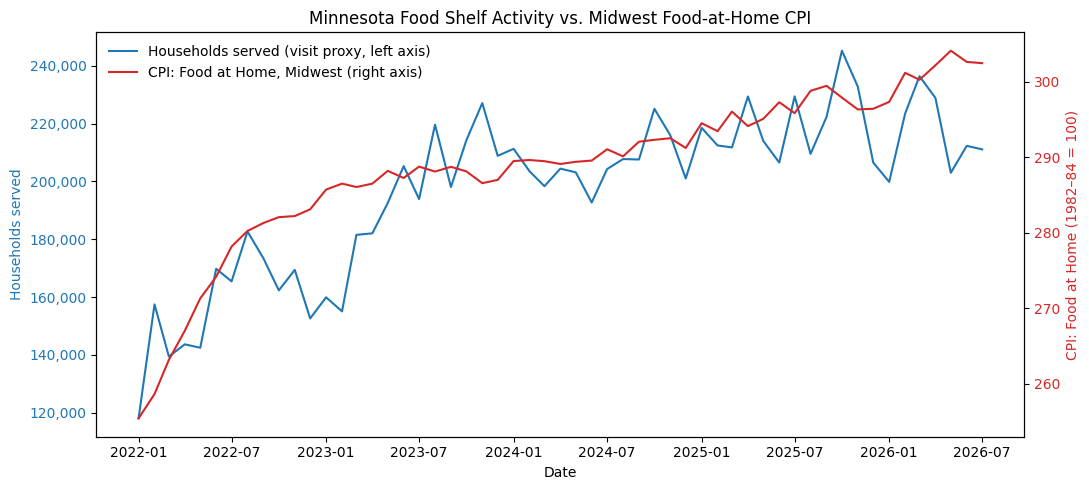

In [45]:
fig, ax1 = plt.subplots(figsize=(11, 5))

line1, = ax1.plot(
    statewide["date"], statewide["visits"],
    color="tab:blue", label="Households served (visit proxy, left axis)"
)
ax1.set_xlabel("Date")
ax1.set_ylabel("Households served", color="tab:blue")
ax1.tick_params(axis="y", labelcolor="tab:blue")
ax1.yaxis.set_major_formatter(mpl.ticker.StrMethodFormatter("{x:,.0f}"))

ax2 = ax1.twinx()
line2, = ax2.plot(
    statewide["date"], statewide["cpi"],
    color="tab:red", label="CPI: Food at Home, Midwest (right axis)"
)
ax2.set_ylabel("CPI: Food at Home (1982–84 = 100)", color="tab:red")
ax2.tick_params(axis="y", labelcolor="tab:red")

# One legend for both axes
ax1.legend(handles=[line1, line2], loc="upper left", frameon=False)

plt.title("Minnesota Food Shelf Activity vs. Midwest Food-at-Home CPI")
fig.tight_layout()
plt.show()

> **What this result means:** The chart overlays statewide households served with the Midwest food-at-home CPI. Both trend upward together. This is the first hint of a relationship, but also a warning: two series that both rise over time will look correlated even if one is not driving the other. The next sections address this.

### 4.2 Raw level correlation

> **Purpose:** As a baseline, this section computes the simple correlation between the raw (non-detrended) level of each activity metric and the raw CPI level, to see how strong the 'eyeball' relationship from the chart above actually is numerically.

In [ ]:
print(
    "Raw level correlations:"
)

for metric in [
    "visits",
    "individuals",
    "pounds"
]:
    corr = statewide[metric].corr(
        statewide["cpi"]
    )

    print(
        f"{metric}: {corr:.3f}"
    )

Raw level correlations:
visits: 0.838
individuals: 0.840
pounds: 0.701


> **What this result means:** All three raw-level correlations are high (households served, the `visits` column: 0.838; `individuals`: 0.840; `pounds`: 0.701). This is very likely a trend-driven correlation rather than evidence that prices drive food-shelf demand. Both CPI and food-shelf activity have risen steadily since 2022, and almost any two upward-trending series over this period correlate strongly. The month-to-month analysis below separates a real relationship from a shared trend.

### 4.3 Month-to-month changes

> **Purpose:** To remove the shared upward trend from the raw-level correlation above, this section converts each series into month-over-month percentage change, which isolates short-term co-movement rather than long-term drift.

In [ ]:
# Calculate monthly percentage changes.

for col in [
    "visits",
    "individuals",
    "pounds",
    "cpi"
]:
    statewide[
        f"{col}_pct_change"
    ] = (
        statewide[col]
        .pct_change()
        * 100
    )

change_cols = [
    "date",
    "visits_pct_change",
    "individuals_pct_change",
    "pounds_pct_change",
    "cpi_pct_change"
]

print(
    statewide[change_cols].head(10)
)

        date  visits_pct_change  individuals_pct_change  pounds_pct_change  \
0 2022-01-01                NaN                     NaN                NaN   
1 2022-02-01          33.358740               -3.325362         -12.420995   
2 2022-03-01         -11.439639               24.720392          22.029939   
3 2022-04-01           3.023176                9.263960           3.908068   
4 2022-05-01          -0.827579                0.334157           1.920912   
5 2022-06-01          19.166497                5.920803           3.303111   
6 2022-07-01          -2.565492               -3.961041          -5.755598   
7 2022-08-01          10.425784               10.420873          12.744543   
8 2022-09-01          -5.080905               -3.792102          -6.462558   
9 2022-10-01          -6.382279               -2.019153           6.631322   

   cpi_pct_change  
0             NaN  
1        1.260078  
2        1.757934  
3        1.465352  
4        1.601867  
5        1.062010  
6

> **What this result means:** The percentage-change table confirms the transformation worked — each column now shows the month-to-month swing rather than a cumulative level. These percent-change columns are what the rest of the correlation and regression analysis uses instead of raw levels.
>
> One early value stands out: households (the `visits` column) jumped +33.4% from January to February 2022 while individuals fell 3.3%. Opposite movements of this size point to a reporting change rather than a real shift in demand (see the residual analysis in 7.3).

### 4.4 Same-month relationship

> **Purpose:** With the trend removed, this step re-tests the correlation between CPI changes and activity changes within the same month, to see whether the strong raw-level relationship survives once the shared trend is stripped out.

In [ ]:
print(
    "Same-month correlations:"
)

for metric in [
    "visits",
    "individuals",
    "pounds"
]:
    corr = statewide[
        f"{metric}_pct_change"
    ].corr(
        statewide["cpi_pct_change"]
    )

    print(
        f"{metric}: {corr:.3f}"
    )

Same-month correlations:
visits: -0.006
individuals: 0.075
pounds: -0.080


> **What this result means:** Once the shared trend is removed, the same-month correlations are essentially zero (households −0.006, individuals 0.075, pounds −0.080; all p > 0.5). The high raw-level correlation was a trend artifact. There is no evidence that food-shelf activity moves in the same month that grocery prices do.

## 5. Q4-B — Does the response happen at once, or is there a delay?

### 5.1 Lag analysis (0–3 months)

> **Purpose:** Food-shelf usage may not respond to a price change in the same month it happens — people may only turn to food shelves after a price increase has persisted for a month or more. This section tests correlations at 0-3 month lags to look for a delayed relationship instead of just a same-month one.

In [ ]:
lag_results = []

for metric in [
    "visits",
    "individuals",
    "pounds"
]:

    for lag in range(0, 4):

        corr = statewide[
            f"{metric}_pct_change"
        ].corr(
            statewide["cpi_pct_change"].shift(lag)
        )

        lag_results.append({
            "metric": metric,
            "CPI_lag_months": lag,
            "correlation": corr
        })

lag_results = pd.DataFrame(
    lag_results
)

print(
    lag_results.round(3)
)

         metric  CPI_lag_months  correlation
0        visits               0       -0.006
1        visits               1        0.334
2        visits               2        0.048
3        visits               3        0.026
4   individuals               0        0.075
5   individuals               1        0.388
6   individuals               2        0.048
7   individuals               3       -0.043
8        pounds               0       -0.080
9        pounds               1        0.260
10       pounds               2        0.071
11       pounds               3        0.061


> **What this result means:** A signal appears at a 1-month lag: households 0.334 (p = 0.014), individuals 0.388 (p = 0.004), and pounds 0.260 (p = 0.060). At 2–3 months the correlations fall back near zero (|r| ≤ 0.07).
>
> With about 53 monthly observations, a correlation must exceed roughly 0.27 to be significant at 5%. The 1-month effect is therefore statistically clear for households and individuals and borderline for pounds. Because this lag was chosen after comparing four candidates, Section 8 tests it further.

In [ ]:
lag_table = lag_results.pivot(
    index="metric",
    columns="CPI_lag_months",
    values="correlation"
)

print(
    lag_table.round(3)
)

CPI_lag_months      0      1      2      3
metric                                    
individuals     0.075  0.388  0.048 -0.043
pounds         -0.080  0.260  0.071  0.061
visits         -0.006  0.334  0.048  0.026


> **What this result means:** This pivoted table shows the same results in compact form: within 0–3 months, the lag-1 column is the highest for every metric, while lags 0, 2, and 3 are close to zero.

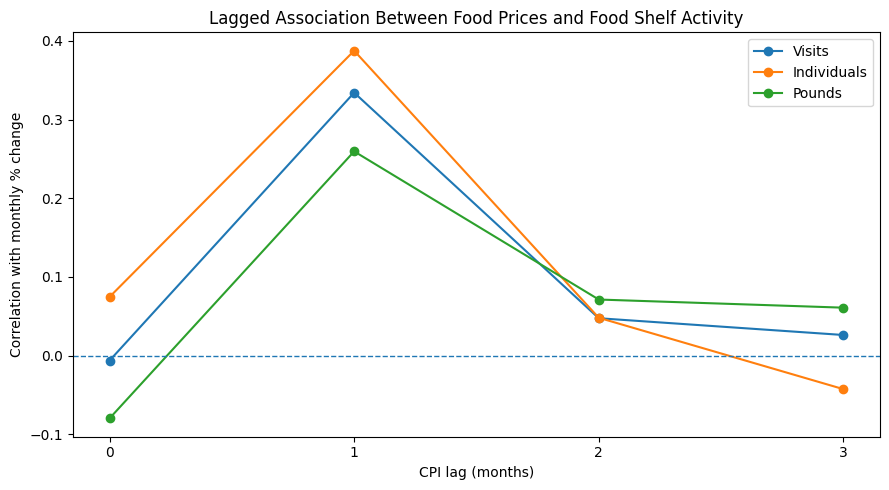

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))

for metric in [
    "visits",
    "individuals",
    "pounds"
]:

    subset = lag_results[
        lag_results["metric"] == metric
    ]

    ax.plot(
        subset["CPI_lag_months"],
        subset["correlation"],
        marker="o",
        label=metric.capitalize()
    )

ax.axhline(
    0,
    linestyle="--",
    linewidth=1
)

ax.set_xlabel(
    "CPI lag (months)"
)

ax.set_ylabel(
    "Correlation with monthly % change"
)

ax.set_title(
    "Lagged Association Between Food Prices and Food Shelf Activity"
)

ax.set_xticks(
    [0, 1, 2, 3]
)

ax.legend()

plt.tight_layout()
plt.show()

> **What this result means:** Within the 0–3 month window, each metric's correlation peaks at a 1-month CPI lag. Whether that peak reflects a real delayed response is tested in Section 8, which extends the window in both directions.

### 5.2 Identify the strongest lag for each metric

> **Purpose:** Rather than relying on eyeballing the table or chart, this step programmatically picks out the single best-correlated lag for each metric, to state a clear, specific finding for the slides.

In [ ]:
best_lags = (
    lag_results
    .sort_values(
        ["metric", "correlation"],
        ascending=[True, False]
    )
    .groupby("metric")
    .head(1)
    .sort_values("metric")
)

print(
    best_lags.round(3)
)

        metric  CPI_lag_months  correlation
5  individuals               1        0.388
9       pounds               1        0.260
1       visits               1        0.334


> **What this result means:** Within lags 0–3, a 1-month lag gives the highest correlation for all three metrics (individuals 0.388, households 0.334, pounds 0.260). Section 8 shows this peak should not be read as a precise one-month delay: similar correlations also appear when activity *leads* CPI, even after removing seasonality.

## 6. Q4-D — Are there cyclical patterns that prices do not explain?

### 6.1 Month-of-year averages (raw)

> **Purpose:** Before concluding anything causal from the CPI relationship, it's worth checking whether food-shelf activity simply has a recurring seasonal pattern (e.g., higher in certain months regardless of price) — seasonality is a separate explanation that the regression section later needs to control for.

In [ ]:
statewide["month"] = (
    statewide["date"].dt.month
)

seasonality = (
    statewide
    .groupby("month")
    .agg(
        visits=("visits", "mean"),
        individuals=("individuals", "mean"),
        pounds=("pounds", "mean"),
        cpi=("cpi", "mean")
    )
)

print(
    seasonality.round(1)
)

         visits  individuals      pounds    cpi
month                                          
1      181520.0     552642.6  10510111.6  284.5
2      190376.6     548190.6   9977500.2  285.9
3      193485.6     588382.6  10733079.6  287.0
4      197671.4     603825.4  10798389.0  287.8
5      191021.8     584246.4  10724617.8  289.6
6      197319.4     593661.8  10781164.7  290.2
7      200808.4     601753.2  11009232.9  291.3
8      204881.2     613731.8  11619375.0  289.3
9      200324.2     601511.0  10788204.3  290.4
10     211711.8     643368.5  11775030.0  290.1
11     211285.2     651303.8  11915488.1  289.4
12     192245.8     583365.5  11266187.1  289.4


> **What this result means:** Raw month-of-year averages suggest activity peaks in October–November and is lowest in January. However, this table mixes seasonality with the strong upward trend: January–July averages include 2026 (the highest-volume year), while August–December do not. Treat it as descriptive only; the detrended seasonal index (6.4) is the version to cite.

### 6.2 Plot: households and individuals by month

> **Purpose:** This chart visualizes the month-of-year averages for visits and individuals computed above, making the seasonal peak/trough pattern easier to communicate on a slide than a table of numbers.

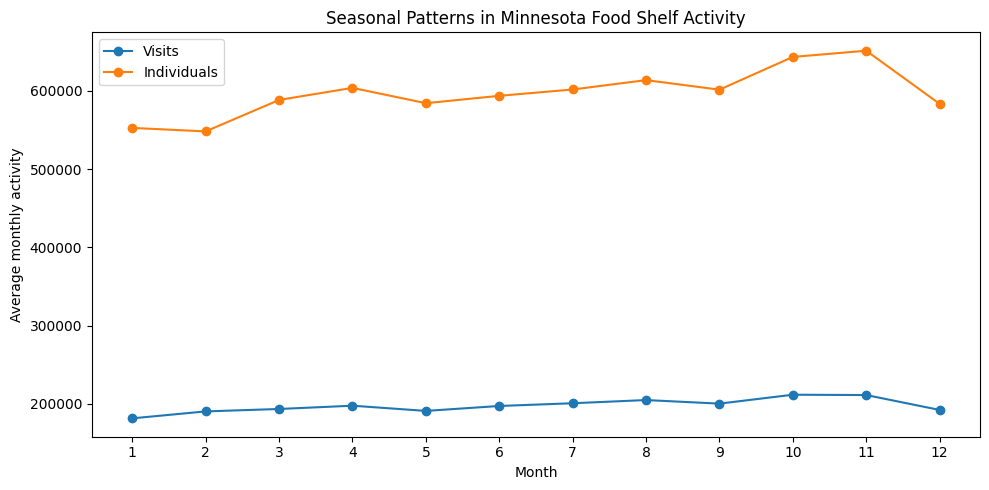

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    seasonality.index,
    seasonality["visits"],
    marker="o",
    label="Visits"
)

ax.plot(
    seasonality.index,
    seasonality["individuals"],
    marker="o",
    label="Individuals"
)

ax.set_xlabel("Month")
ax.set_ylabel(
    "Average monthly activity"
)

ax.set_title(
    "Seasonal Patterns in Minnesota Food Shelf Activity"
)

ax.set_xticks(
    range(1, 13)
)

ax.legend()

plt.tight_layout()
plt.show()

These raw averages are descriptive; see the detrended index (6.4) for the trend-adjusted pattern.

> **What this result means:** The chart shows both visits and individuals following a similar seasonal shape — both climbing through spring/summer and peaking in fall before dropping in winter/January — reinforcing that the two metrics move together seasonally, as expected since both are different ways of counting the same underlying food-shelf usage.

### 6.3 Plot: pounds by month

> **Purpose:** Pounds distributed is on a very different scale (millions vs. hundreds of thousands) than visits/individuals, so it needs its own chart rather than being squeezed onto the same axis, where it would be invisible next to the other two metrics.

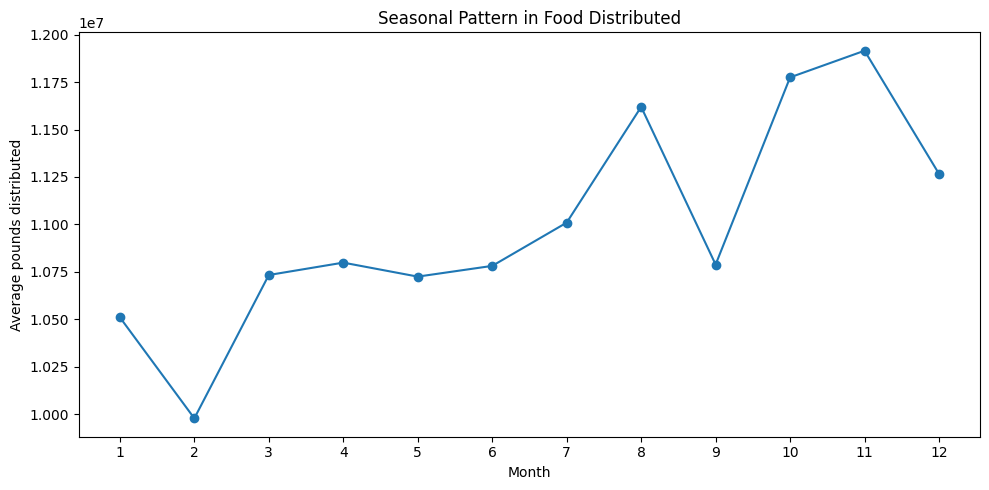

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    seasonality.index,
    seasonality["pounds"],
    marker="o"
)

ax.set_xlabel("Month")
ax.set_ylabel("Average pounds distributed")

ax.set_title(
    "Seasonal Pattern in Food Distributed"
)

ax.set_xticks(
    range(1, 13)
)

plt.tight_layout()
plt.show()

These raw averages are descriptive; see the detrended index (6.4) for the trend-adjusted pattern.

> **What this result means:** Pounds distributed shows the same general seasonal shape as visits and individuals — rising through the year and peaking around October-November — confirming the seasonal pattern holds across all three ways of measuring food-shelf activity, not just visit counts.

### 6.4 Detrended seasonal index

> **Purpose:** To answer "are there cyclical patterns that prices do not explain," seasonality must first be separated from the upward trend. Each month is compared with a centered 12-month moving average, so a value of 1.05 means 5% above that period's trend.

       visits_seasonal_ratio  individuals_seasonal_ratio  pounds_seasonal_ratio  n_years
month                                                                                   
1                      0.969                       0.979                  0.985        4
2                      0.968                       0.966                  0.944        4
3                      0.987                       0.993                  0.977        3
4                      1.018                       1.021                  0.985        3
5                      0.999                       0.993                  0.995        3
6                      0.984                       0.975                  0.973        3
7                      1.022                       1.008                  0.995        4
8                      1.052                       1.043                  1.062        4
9                      1.019                       1.006                  0.978        4
10                   

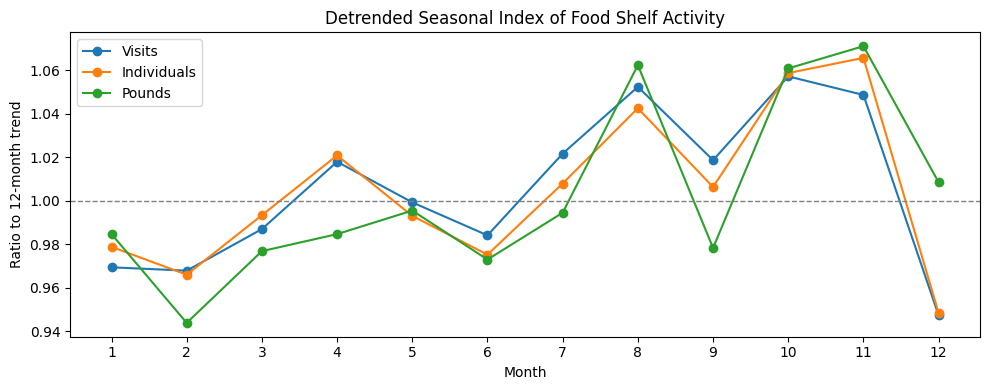

In [ ]:
# Raw month-of-year averages mix trend with seasonality (Jan-Jul include 2026, Aug-Dec do not).
# Ratio to a centered 12-month moving average removes the trend first.
METRICS = ["visits", "individuals", "pounds"]

for m in METRICS:
    trend = statewide[m].rolling(12, center=True).mean()
    statewide[f"{m}_seasonal_ratio"] = statewide[m] / trend

ratio_cols = [f"{m}_seasonal_ratio" for m in METRICS]
seasonal_index = statewide.groupby("month")[ratio_cols].mean()
seasonal_n = statewide.groupby("month")[ratio_cols[0]].count().rename("n_years")
print(seasonal_index.round(3).join(seasonal_n).to_string())

fig, ax = plt.subplots(figsize=(10, 4))
for m in METRICS:
    ax.plot(seasonal_index.index, seasonal_index[f"{m}_seasonal_ratio"], marker="o", label=m.capitalize())
ax.axhline(1.0, ls="--", lw=1, color="gray")
ax.set_xticks(range(1, 13)); ax.set_xlabel("Month"); ax.set_ylabel("Ratio to 12-month trend")
ax.set_title("Detrended Seasonal Index of Food Shelf Activity"); ax.legend()
plt.tight_layout(); plt.show()

> **What this result means:** After removing the trend, a clear calendar cycle remains that has nothing to do with prices.
> - **Peaks:** August (4–6% above trend) and October–November (5–7% above).
> - **Troughs:** December (households and individuals about 5% below) and January–February (2–6% below).
> - **Metric differences:** In December, households and individuals drop below trend but pounds stays at trend (1.008), meaning more food per household around the holidays. The December drop may also partly reflect holiday distributions recorded outside the "Reg" fields; this is worth confirming with TFG.
> - **Calendar length:** February's dip is partly mechanical, because February has about 10% fewer days than January or March.
>
> Each month's index averages only 3–4 years, since the centered moving average cannot be computed for the first and last six months. Individual values are approximate; the overall shape (late-summer and pre-holiday peaks, December–February lows) is the robust finding.

## 7. Regression: price effect after controlling for seasonality

Answers Q4-A and Q4-B with seasonal controls, compares all three metrics (Q4-C), and shows what prices leave unexplained (Q4-D).

### 7.1 Same-month regression with quarter fixed effects

> **Purpose:** Given the seasonality confirmed above, a regression of activity change on CPI change needs to control for which quarter of the year it is — otherwise, the CPI coefficient could just be picking up a seasonal pattern that has nothing to do with prices. Quarter (rather than month) dummies are used here specifically to preserve degrees of freedom, since the dataset only has ~53-55 monthly observations and a full set of 11 month dummies would leave too few observations per parameter to estimate anything reliably.

In [ ]:
reg_data = statewide.dropna(
    subset=["cpi_pct_change", "visits_pct_change", "individuals_pct_change", "pounds_pct_change"]
).copy()

# Use quarter instead of month fixed effects: 3 dummy variables instead of 11,
# which leaves far more degrees of freedom for only 53 monthly observations.
reg_data["quarter"] = reg_data["date"].dt.quarter

model_visits = smf.ols("visits_pct_change ~ cpi_pct_change + C(quarter)", data=reg_data).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
print(model_visits.summary())

model_individuals = smf.ols("individuals_pct_change ~ cpi_pct_change + C(quarter)", data=reg_data).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
print(model_individuals.summary())

model_pounds = smf.ols("pounds_pct_change ~ cpi_pct_change + C(quarter)", data=reg_data).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
print(model_pounds.summary())

                            OLS Regression Results                            
Dep. Variable:      visits_pct_change   R-squared:                       0.052
Model:                            OLS   Adj. R-squared:                 -0.025
Method:                 Least Squares   F-statistic:                     1.599
Date:                Sat, 10 Oct 2026   Prob (F-statistic):              0.189
Time:                        03:38:07   Log-Likelihood:                -191.13
No. Observations:                  54   AIC:                             392.3
Df Residuals:                      49   BIC:                             402.2
Df Model:                           4                                         
Covariance Type:                  HAC                                         
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept           4.7500      2.325     

> **What this result means:** With quarter controls and HAC (Newey-West) standard errors, same-month CPI change is not significant for any metric (households coef −1.38, p = 0.45; individuals −0.02, p = 0.99; pounds −0.91, p = 0.66), and adjusted R² is negative. This confirms the near-zero same-month correlations: there is no same-month price response, even after accounting for seasonality.
>
> HAC standard errors are used because the residuals are autocorrelated (Durbin-Watson ≈ 2.4–2.8). Under that condition, ordinary standard errors would be unreliable.

### 7.2 Lagged regression (CPI change one month earlier)

> **Purpose:** The lag analysis above found the highest correlation at a 1-month lag rather than in the same month. This section re-runs the regression using CPI change lagged by one month instead of same-month CPI change, to see whether that association holds once seasonality (quarter) is controlled for too.

In [ ]:
reg_data["cpi_change_lag1"] = reg_data["cpi_pct_change"].shift(1)
reg_data_lag1 = reg_data.dropna(subset=["cpi_change_lag1"]).copy()

model_visits_lag1 = smf.ols("visits_pct_change ~ cpi_change_lag1 + C(quarter)", data=reg_data_lag1).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
print(model_visits_lag1.summary())

model_individuals_lag1 = smf.ols("individuals_pct_change ~ cpi_change_lag1 + C(quarter)", data=reg_data_lag1).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
print(model_individuals_lag1.summary())

model_pounds_lag1 = smf.ols("pounds_pct_change ~ cpi_change_lag1 + C(quarter)", data=reg_data_lag1).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
print(model_pounds_lag1.summary())

                            OLS Regression Results                            
Dep. Variable:      visits_pct_change   R-squared:                       0.116
Model:                            OLS   Adj. R-squared:                  0.042
Method:                 Least Squares   F-statistic:                     2.740
Date:                Sat, 10 Oct 2026   Prob (F-statistic):             0.0392
Time:                        03:38:07   Log-Likelihood:                -178.18
No. Observations:                  53   AIC:                             366.4
Df Residuals:                      48   BIC:                             376.2
Df Model:                           4                                         
Covariance Type:                  HAC                                         
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept          -0.0079      1.958     

> **What this result means:** Replacing same-month CPI with last month's CPI change makes the price coefficient positive and significant for all three metrics with HAC standard errors: households 3.85 (p = 0.019), individuals 4.95 (p = 0.002), and pounds 3.67 (p = 0.008).
>
> The fit is still modest (adjusted R² 0.12 for individuals, about 0.01 for pounds), so prices explain only a small share of month-to-month swings. Pounds is significant here but borderline in the simple correlation (p = 0.06); the difference comes from the quarter controls and HAC errors. Pounds should be presented as the weakest of the three.
>
> These coefficients measure association, not a confirmed one-month causal delay; see the lead-lag tests in 8.1–8.2.

### 7.3 What lagged CPI does not explain: residuals and policy events

> **Purpose:** The residuals show the month-to-month movement left over after lagged CPI and quarter are accounted for. Any systematic pattern here is a driver that prices do not explain.

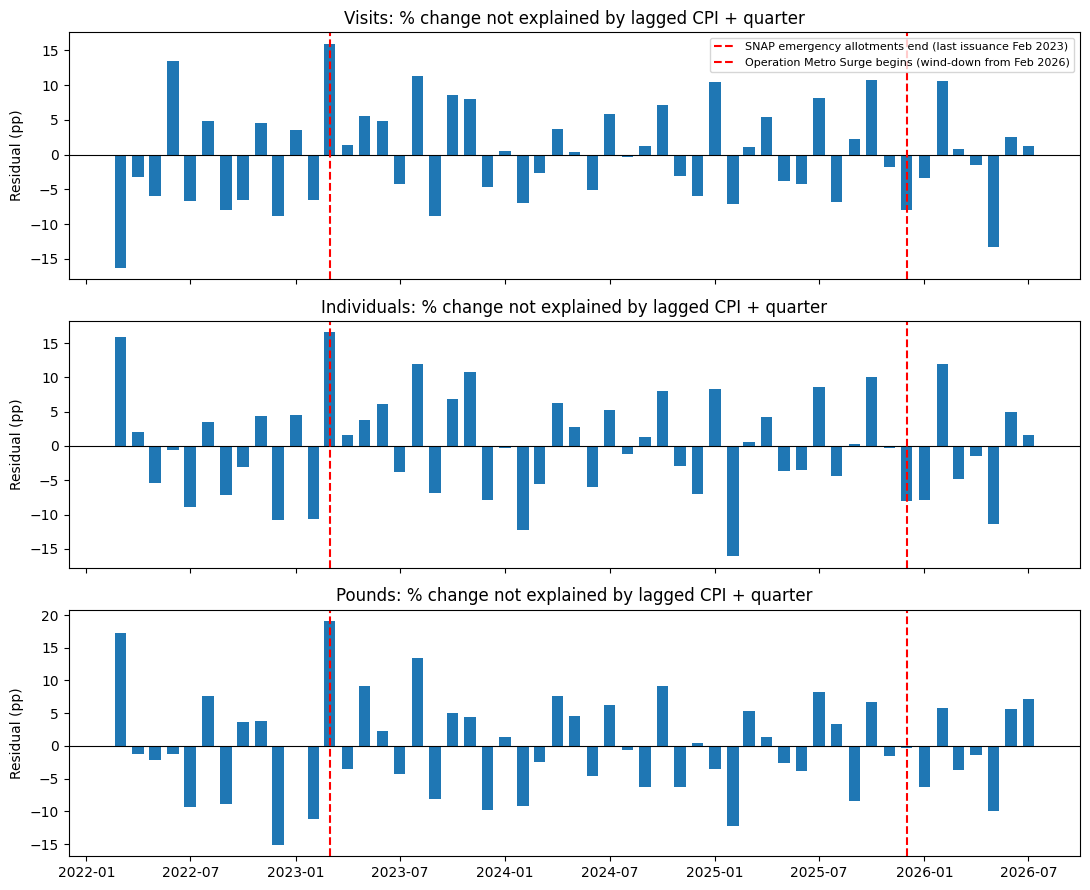

Mean residual by calendar month (pp):
       Visits  Individuals  Pounds
month                             
1        2.80         1.16   -2.15
2       -2.52        -6.78   -6.71
3       -0.22         4.49    7.09
4        1.13         2.55    0.55
5       -3.42        -2.76   -0.19
6        2.30         0.21   -0.36
7        0.88         0.53    1.61
8        2.25         2.46    5.93
9       -3.35        -3.12   -7.93
10       4.95         5.46    6.11
11       1.91         2.97    0.11
12      -6.86        -8.43   -6.22

Largest unexplained months (visits):
    Visits  Individuals  Pounds       date
2   -16.29        15.82   17.31 2022-03-01
14   16.00        16.58   19.09 2023-03-01
5    13.46        -0.55   -1.26 2022-06-01
52  -13.31       -11.32   -9.88 2026-05-01
19   11.26        11.97   13.45 2023-08-01
45   10.70         9.99    6.63 2025-10-01


In [ ]:
# Event dates confirmed from BLS/USDA and news sources (see markdown below).
EVENTS = {
    "2023-03-01": "SNAP emergency allotments end (last issuance Feb 2023)",
    "2025-12-01": "Operation Metro Surge begins (wind-down from Feb 2026)",
}

lag_models = {"Visits": model_visits_lag1, "Individuals": model_individuals_lag1,
              "Pounds": model_pounds_lag1}

fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
for ax, (label, model) in zip(axes, lag_models.items()):
    dates = reg_data_lag1.loc[model.resid.index, "date"]
    ax.bar(dates, model.resid, width=20)
    ax.axhline(0, color="black", lw=0.8)
    for d, txt in EVENTS.items():
        ax.axvline(pd.Timestamp(d), color="red", ls="--", label=txt)
    ax.set_title(f"{label}: % change not explained by lagged CPI + quarter")
    ax.set_ylabel("Residual (pp)")
axes[0].legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()

resid_df = pd.DataFrame({k: m.resid for k, m in lag_models.items()})
resid_df["date"] = reg_data_lag1.loc[resid_df.index, "date"]

print("Mean residual by calendar month (pp):")
print(resid_df.assign(month=resid_df["date"].dt.month)
      .groupby("month")[list(lag_models)].mean().round(2).to_string())

print("\nLargest unexplained months (visits):")
print(resid_df.reindex(resid_df["Visits"].abs().sort_values(ascending=False).index)
      .head(6).round(2).to_string())

In [ ]:
print(resid_df[resid_df["date"] >= "2025-09-01"].round(2).to_string())

    Visits  Individuals  Pounds       date
44    2.24         0.35   -8.44 2025-09-01
45   10.70         9.99    6.63 2025-10-01
46   -1.81        -0.29   -1.53 2025-11-01
47   -7.99        -8.09   -0.29 2025-12-01
48   -3.34        -7.94   -6.31 2026-01-01
49   10.63        11.94    5.74 2026-02-01
50    0.81        -4.85   -3.70 2026-03-01
51   -1.54        -1.45   -1.36 2026-04-01
52  -13.31       -11.32   -9.88 2026-05-01
53    2.59         4.98    5.67 2026-06-01
54    1.31         1.55    7.10 2026-07-01


> **What this result means:** Two kinds of non-price patterns remain.
>
> 1. **A within-quarter calendar cycle that quarter dummies cannot capture.** Mean residuals are strongly negative in December (−6 to −8 pp) and positive in October (+5 to +6 pp). Both months are in Q4, so a quarter dummy averages them away. Residuals are also negative in February and September. This matches the detrended seasonal index. Because of this cycle, an individual month's residual should be compared with the typical residual for that calendar month, not with zero.
> 2. **Policy and community shocks.**
>    - **SNAP emergency allotments ending.** The largest unexplained increase is March 2023 (+16 to +19 pp in all three metrics), the first month after SNAP emergency allotments ended (last issuance February 2023). This is the clearest single event in the series, and it coincides with a cut in benefit levels, not a jump in grocery prices (see Q5).
>    - **Operation Metro Surge.** This federal immigration enforcement operation began December 1, 2025, escalated in early January 2026, and wound down from February 2026. December 2025 is in line with a typical December. January 2026 falls below a typical January (households −6 pp, individuals −9 pp relative to the January average), and February 2026 rises well above a typical February (+13 to +19 pp). This dip-then-rebound matches reports that visits first dropped sharply as families avoided leaving home and then rose to record levels. Combining both months, activity still ends 7–10 pp above normal, so the rebound is more than recovery from a low January. This is consistent with, not proof of, an effect: SNAP changes overlapped this period, and The Food Group shifted part of its response to home delivery ([TFG](https://www.thefoodgroupmn.org/news/fear-should-never-be-a-barrier-to-food-the-food-group-and-partners-respond-to-operation-metro-surge/)), which may not be recorded in site-level counts.
>
> Some large residuals have no identified cause. May 2026 is about 10 pp below a typical May in all three metrics, and October 2025 is about 6 pp above a typical October. One large residual is a data artifact rather than demand. In March 2022, households are −16 pp while individuals and pounds are +16 to +17 pp. The metrics move in opposite directions right after an unexplained +33% households spike in February 2022, which points to a reporting issue in that month.

### 7.4 (Q4-C) Regression summary: all three metrics side by side

> **Purpose:** This builds a small, slide-ready table collapsing all six regression models (3 metrics × same-month vs. 1-month-lag) down to just their CPI coefficients, so the comparison between same-month and lagged effects can be presented in one glance rather than six separate regression summaries.

In [ ]:
typical_cpi_change = reg_data_lag1["cpi_change_lag1"].median()

rows = []
for label, m_same, m_lag in [
    ("Visits", model_visits, model_visits_lag1),
    ("Individuals", model_individuals, model_individuals_lag1),
    ("Pounds", model_pounds, model_pounds_lag1),
]:
    rows.append({
        "Metric": label,
        "Same-month coef": m_same.params["cpi_pct_change"],
        "Same-month p (HAC)": m_same.pvalues["cpi_pct_change"],
        "1-month-lag coef": m_lag.params["cpi_change_lag1"],
        "1-month-lag p (HAC)": m_lag.pvalues["cpi_change_lag1"],
        "Effect of typical CPI month (pp)": m_lag.params["cpi_change_lag1"] * typical_cpi_change,
    })

reg_summary = pd.DataFrame(rows)
print(f"Typical monthly CPI change: {typical_cpi_change:.3f}%")
print(reg_summary.round(4).to_string(index=False))

Typical monthly CPI change: 0.224%
     Metric  Same-month coef  Same-month p (HAC)  1-month-lag coef  1-month-lag p (HAC)  Effect of typical CPI month (pp)
     Visits          -1.3788              0.4463             3.852               0.0189                            0.8611
Individuals          -0.0162              0.9948             4.948               0.0018                            1.1062
     Pounds          -0.9076              0.6607             3.670               0.0081                            0.8204


> **What this result means:** Every same-month coefficient is small, negative, and insignificant, while every 1-month-lag coefficient is positive and significant (HAC p ≤ 0.02). Even taken at face value, the association is small: a typical monthly CPI increase (+0.22%) corresponds to about +0.8 to +1.1 percentage points of activity change.
>
> For comparison, seasonal swings in the detrended index are ±5%, and the SNAP emergency-allotment shock was +16 to +19 pp. Grocery prices are a minor driver of month-to-month activity compared with the calendar and benefit policy.

## 8. Robustness checks

> **Purpose:** The 1-month-lag result was selected after comparing several lags, on a series whose site composition changes over time. These checks test whether it survives:
> 1. A falsification test (does activity also "predict" future CPI?)
> 2. The same test after removing calendar-month seasonality
> 3. A fixed set of sites
> 4. Excluding the interpolated CPI months
> 5. A different change measure (year over year)

### 8.1 Lead–lag cross-correlation with p-values (falsification test)

In [ ]:
from scipy import stats

def lag_corr_table(df, x_col, y_suffix, lags):
    """Correlate each metric with x_col shifted by k months (k > 0: CPI leads activity)."""
    rows = []
    for metric in METRICS:
        for k in lags:
            d = pd.concat([df[x_col].shift(k), df[f"{metric}{y_suffix}"]], axis=1).dropna()
            r, p = stats.pearsonr(d.iloc[:, 0], d.iloc[:, 1])
            rows.append({"metric": metric, "lag": k, "r": r, "p": p, "n": len(d)})
    return pd.DataFrame(rows)

xcorr = lag_corr_table(statewide, "cpi_pct_change", "_pct_change", range(-3, 7))
print("Correlation (negative lag = activity leads CPI):")
print(xcorr.pivot(index="metric", columns="lag", values="r").round(3).to_string())
print("\np-values:")
print(xcorr.pivot(index="metric", columns="lag", values="p").round(3).to_string())

Correlation (negative lag = activity leads CPI):
lag             -3     -2     -1      0      1      2      3      4      5      6
metric                                                                           
individuals -0.014  0.307 -0.030  0.075  0.388  0.048 -0.043  0.040 -0.176  0.252
pounds       0.004  0.239 -0.049 -0.080  0.260  0.071  0.061  0.041 -0.037  0.167
visits       0.030  0.244  0.099 -0.006  0.334  0.048  0.026  0.073 -0.197  0.181

p-values:
lag             -3     -2     -1      0      1      2      3      4      5      6
metric                                                                           
individuals  0.924  0.027  0.829  0.591  0.004  0.734  0.767  0.785  0.226  0.084
pounds       0.979  0.088  0.726  0.567  0.060  0.615  0.671  0.778  0.802  0.256
visits       0.837  0.081  0.482  0.964  0.014  0.738  0.855  0.613  0.175  0.218


> **What this result means:** The 1-month lag (CPI leading activity) is significant for households and individuals. However, the falsification test does not pass: activity also correlates with the CPI change two months *later* (lag −2: individuals 0.307, p = 0.027; households 0.244 and pounds 0.239, p ≈ 0.08–0.09). Food-shelf use cannot cause Midwest grocery prices, so the next check tests whether a shared seasonal rhythm explains this.

### 8.2 Lead–lag after removing calendar-month means

> **Purpose:** If both series simply share a seasonal rhythm, removing each calendar month's average should eliminate the "activity leads CPI" correlation while leaving a genuine delayed response intact.

In [ ]:
# Remove each calendar month's average % change from both CPI and activity,
# so correlations cannot come from a shared seasonal rhythm.
sw_ds = statewide.copy()
for c in ["cpi_pct_change"] + [f"{m}_pct_change" for m in METRICS]:
    sw_ds[c] = sw_ds[c] - sw_ds.groupby("month")[c].transform("mean")

xcorr_ds = lag_corr_table(sw_ds, "cpi_pct_change", "_pct_change", range(-3, 7))
print(xcorr_ds.pivot(index="metric", columns="lag", values="r").round(3).to_string())
print(xcorr_ds.pivot(index="metric", columns="lag", values="p").round(3).to_string())

lag             -3     -2     -1      0      1      2      3      4      5      6
metric                                                                           
individuals -0.060  0.391  0.090  0.081  0.362 -0.056 -0.031  0.166 -0.236  0.300
pounds      -0.023  0.266  0.048 -0.015  0.254 -0.077 -0.022  0.165 -0.134  0.257
visits      -0.081  0.343  0.185 -0.043  0.259 -0.040  0.046  0.193 -0.236  0.202
lag             -3     -2     -1      0      1      2      3      4      5      6
metric                                                                           
individuals  0.675  0.004  0.523  0.560  0.008  0.693  0.830  0.248  0.102  0.038
pounds       0.874  0.056  0.734  0.914  0.067  0.585  0.881  0.251  0.358  0.077
visits       0.573  0.013  0.186  0.758  0.061  0.781  0.747  0.179  0.102  0.168


> **What this result means:** Removing calendar-month averages does not eliminate the lead correlation; it strengthens it. Lag −2 rises to 0.391 for individuals (p = 0.004) and 0.343 for households (p = 0.013), now at least as large as lag +1 (individuals 0.362, p = 0.008; households 0.259, p = 0.061; pounds 0.254, p = 0.067). Seasonality is therefore not the explanation.
>
> Food-shelf use cannot cause Midwest grocery prices, so a correlation in that direction is a warning about the method, not a finding. Two features of this data make such correlations likely: there are only about 50 monthly observations, and 30 lag-metric combinations were tested, so some significant values are expected by chance.
>
> **Conclusion:** the data does not support a precise one-month delay. It supports a weaker but defensible statement — periods of faster food inflation coincide with faster growth in food-shelf activity, while the response is not visible within the same month.

### 8.3 (Q4-C) Balanced panel: sites reporting in every month

In [ ]:
MIN_MONTH_SHARE = 1.0   # lower to 0.95 if too few sites qualify

n_months = fs_valid["date"].nunique()
months_per_site = fs_valid.groupby("_id_site")["date"].nunique()
balanced_sites = months_per_site[months_per_site >= MIN_MONTH_SHARE * n_months].index
bal = fs_valid[fs_valid["_id_site"].isin(balanced_sites)]

sw_bal = (bal.groupby("date")
          .agg(visits=("HouseholdsReg", lambda x: x.sum(min_count=1)),
               individuals=("IndividualsReg", lambda x: x.sum(min_count=1)),
               pounds=("PoundsReg", lambda x: x.sum(min_count=1)))
          .sort_index().reset_index()
          .merge(statewide[["date", "cpi_pct_change"]], on="date", how="left"))
for m in METRICS:
    sw_bal[f"{m}_pct_change"] = sw_bal[m].pct_change() * 100

print(f"Balanced sites: {len(balanced_sites)} of {fs_valid['_id_site'].nunique()}")
print(f"Share of households covered: {bal['HouseholdsReg'].sum() / fs_valid['HouseholdsReg'].sum():.1%}")

bal_lags = lag_corr_table(sw_bal, "cpi_pct_change", "_pct_change", range(0, 4))
print(bal_lags.pivot(index="metric", columns="lag", values="r").round(3).to_string())
print(bal_lags.pivot(index="metric", columns="lag", values="p").round(3).to_string())

Balanced sites: 304 of 488
Share of households covered: 77.3%
lag              0      1      2      3
metric                                 
individuals  0.056  0.310 -0.016 -0.097
pounds      -0.117  0.218  0.009  0.028
visits      -0.013  0.225 -0.015 -0.042
lag              0      1      2      3
metric                                 
individuals  0.689  0.024  0.909  0.500
pounds       0.401  0.117  0.952  0.844
visits       0.925  0.106  0.918  0.772


> **What this result means:** 304 of 488 sites reported in every month, covering 77% of households. In this fixed-composition series, the 1-month-lag correlation stays positive for all three metrics but is weaker. Individuals (0.310, p = 0.024) remains significant, while households (0.225, p = 0.11) and pounds (0.218, p = 0.12) do not.
>
> Part of the statewide signal therefore comes from sites entering and leaving the reporting pool. Individuals served is the metric whose association with prices is most robust.

### 8.4 Sensitivity: excluding interpolated CPI months

In [ ]:
sw_s = statewide.copy()
interp_affected = pd.to_datetime(["2025-10-01", "2025-11-01"])
sw_s.loc[sw_s["date"].isin(interp_affected), "cpi_pct_change"] = np.nan

sens = lag_corr_table(sw_s, "cpi_pct_change", "_pct_change", [1])
base = xcorr[xcorr["lag"] == 1][["metric", "r", "p"]]
print(base.merge(sens[["metric", "r", "p", "n"]], on="metric",
                 suffixes=("_all_months", "_excl_interp")).round(3).to_string(index=False))

     metric  r_all_months  p_all_months  r_excl_interp  p_excl_interp  n
     visits         0.334         0.014          0.289          0.040 51
individuals         0.388         0.004          0.350          0.012 51
     pounds         0.260         0.060          0.253          0.073 51


> **What this result means:** Excluding the interpolated October–November 2025 CPI changes (n = 51), the lag-1 correlations decline slightly but hold: households 0.289 (p = 0.040), individuals 0.350 (p = 0.012), pounds 0.253 (p = 0.073). The interpolation does not drive the result.

### 8.5 Year-over-year changes

In [ ]:
# YoY removes seasonality by construction. Note: overlapping 12-month windows make
# YoY series smooth, so p-values here are overstated — read the r values, not p.
for col in METRICS + ["cpi"]:
    statewide[f"{col}_yoy"] = statewide[col].pct_change(12) * 100

yoy_lags = lag_corr_table(statewide, "cpi_yoy", "_yoy", range(0, 4))
print(yoy_lags.pivot(index="metric", columns="lag", values="r").round(3).to_string())

lag              0      1      2      3
metric                                 
individuals  0.535  0.552  0.519  0.529
pounds       0.448  0.505  0.470  0.472
visits       0.348  0.333  0.518  0.538


> **What this result means:** Measured year over year, food-price inflation and food-shelf activity growth are clearly positively related (r ≈ 0.33–0.55). Periods of faster grocery inflation coincide with faster growth in demand over the year.
>
> However, the YoY correlations do not single out one lag (individuals are 0.52–0.55 at every lag, and households are actually higher at lags 2–3). Overlapping 12-month windows make both series very smooth, so YoY supports the link at an annual scale but cannot identify timing. The monthly analysis is what shows the response is not immediate.

## 9. Summary and Q4 answers

### 9.1 Final analytical summary table

> **Purpose:** This closing table consolidates the whole Q4 price-relationship analysis — same-month correlation, best lag, and best-lag correlation — into one row per metric, intended as the final reference table for the write-up or slide.

In [ ]:
summary_table = []

for metric in [
    "visits",
    "individuals",
    "pounds"
]:

    metric_lags = lag_results[
        lag_results["metric"] == metric
    ].copy()

    best_row = metric_lags.loc[
        metric_lags["correlation"].idxmax()
    ]

    same_month = metric_lags.loc[
        metric_lags["CPI_lag_months"] == 0,
        "correlation"
    ].iloc[0]

    summary_table.append({
        "Metric": metric,
        "Same_month_corr": same_month,
        "Strongest_lag_months": int(
            best_row["CPI_lag_months"]
        ),
        "Strongest_lag_corr": best_row[
            "correlation"
        ]
    })

summary_table = pd.DataFrame(
    summary_table
)

print(
    summary_table.round(3)
)

        Metric  Same_month_corr  Strongest_lag_months  Strongest_lag_corr
0       visits           -0.006                     1               0.334
1  individuals            0.075                     1               0.388
2       pounds           -0.080                     1               0.260


> **What this result means:** For all three metrics, the same-month correlation with CPI is near zero, and correlations of 0.26–0.39 appear at nearby lags. Lead-lag tests show that similar correlations also appear when activity precedes CPI, even after removing seasonality. The robust finding is co-movement over a period of months, not a specific delay.

### 9.2 Q4 answers

**1. Do more people arrive at food shelves when grocery prices rise?**
Yes, but modestly. Over the year, faster food inflation coincides with faster growth in activity (YoY r ≈ 0.33–0.55). Month to month, a typical +0.22% CPI increase is associated with about +1 percentage point of activity change. That is far smaller than the seasonal swings (±5%) or the SNAP emergency-allotment shock (+16–19 pp).

**2. Does the response happen at once, or is there a delay?**
It is not immediate: same-month correlations are about zero, and same-month regression coefficients are insignificant. Correlations of 0.26–0.39 appear at nearby lags, strongest at one month when only CPI-leading lags are examined. However, falsification tests also find correlations when activity leads CPI by two months, and after removing seasonality these are as strong as the one-month lag. We therefore conclude that food inflation and food-shelf demand move together over periods of several months, but this data (55 months, one regional price series) cannot pin down a precise delay.

**3. Does the response appear in all three metrics?**
Yes in direction, but unequal in strength.
- **Individuals** show the strongest and most consistent association: the lag-1 correlation is significant in every check, including the fixed-site panel.
- **Households** (our visit proxy) show it in the full data but weaken in the fixed-site panel.
- **Pounds** show the weakest association. This is expected, because pounds is also a supply measure: rising prices raise demand but reduce how much food shelves can buy.

**4. Are there other cyclical patterns that prices do not explain?**
Yes, and they are larger than the price effect:
- **A calendar cycle:** peaks in August and October–November, lows in December and January–February.
- **Policy and community shocks:** most clearly March 2023, right after SNAP emergency allotments ended (+16–19 pp). Operation Metro Surge (December 2025 – February 2026) coincides with a below-normal January 2026 followed by a well-above-normal February 2026.

**What The Food Group can do differently**
- **Plan inventory and staffing on the calendar first.** Expect demand about 5–7% above trend in August and October–November, and below trend in December through February.
- **Use food-price inflation as context for donor communication, not as a month-ahead trigger.** When Midwest food-at-home inflation stays elevated for several months, expect faster demand growth over that period; a single month's CPI reading is not a reliable forecast of next month's activity.
- **Watch SNAP benefit changes more closely than grocery prices.** The largest unexplained increase in the data followed a benefit reduction, not a price rise.

**Limitations**
- Households served is not visits (about 28% of TFG's published visit totals).
- The reporting-site count fell 8% in January 2024.
- The CPI is a Midwest urban series, not Minnesota-specific.
- There are only 55 monthly observations.